# Group 05, Project 1, Deliverable 3: EDA, Statistical Inference and Dashboard

**Course:** ACIT 4880, CRN 45883, Set B, Domain D (tariffs and trade)
**Members:** Jashanpreet Singh, Priyanshu Batra, Janek Basi

**Business question (from D1, unchanged):** how did US imports of capital goods, automotive goods and consumer goods move through the 2025 tariff period, and how much of that movement came from price versus volume? Stakeholder: procurement and supply chain teams at US importers.

**Target variable:** `import_value_usd`, the monthly US general import value in US dollars for one partner country and one 5 digit end-use product code.

**Which version of the data we use.** Everything below runs on `data/processed/d2_clean_pre_transform.csv.gz`. This file is saved at the end of D2 Part 4, so it already has the type fixes, duplicate removal, domain fixes, imputation and outlier handling from D2, but none of the log transforms or scaling from D2 Part 5. The transformed version stays for Project 2. The file has 277,592 rows and 22 columns.

We add four readable columns from values that are already in the data (no transformation):
- `effective_tariff_rate` = calculated duty / consumption value, so the share of the goods value that was paid as duty
- `period` = pre-tariff (Jan 2022 to Mar 2025, 39 months) vs post-tariff (Apr 2025 on, 16 months). April 2025 is when the broad "reciprocal" tariffs started.
- `pays_duty` = whether the flow paid any duty at all
- `main_mode` = the transport mode carrying the larger share of the value (vessel, air, or land and other)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LogNorm
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}" if abs(v) < 1000 else f"{v:,.0f}")
sns.set_theme(style="whitegrid")

# Cleaned D2 data, saved after outlier handling (Part 4) and before any log/sqrt transform (Part 5)
df = pd.read_csv("data/processed/d2_clean_pre_transform.csv.gz", parse_dates=["month"],
                 dtype={"cty_code": str, "enduse_code": str, "category_code": str})
TARGET = "import_value_usd"

# A few readable columns built from the raw values (no transformation involved)
df["effective_tariff_rate"] = np.where(df["consumption_value_usd"] > 0,
                                       df["calculated_duty_usd"] / df["consumption_value_usd"], 0.0)
df["period"] = np.where(df["month"] >= "2025-04-01", "Post-tariff (Apr 2025 on)", "Pre-tariff (Jan 2022 to Mar 2025)")
df["pays_duty"] = np.where(df["calculated_duty_usd"] > 0, "Pays duty", "Duty free")
df["main_mode"] = np.select(
    [(df["vessel_value_usd"] >= df["air_value_usd"]) & (df["vessel_value_usd"] > 0), df["air_value_usd"] > 0],
    ["Vessel", "Air"], default="Land and other")

CONT = ["import_value_usd", "consumption_value_usd", "dutiable_value_usd", "calculated_duty_usd",
        "air_value_usd", "vessel_value_usd", "container_value_usd", "air_weight_kg", "vessel_weight_kg",
        "price_index", "effective_tariff_rate"]
def fmt_p(p):
    # with n in the hundreds of thousands, p can be smaller than the smallest float and print as 0
    return "< 1e-300 (too small to store as a float, effectively 0)" if p == 0 else f"{p:.3g}"

print(df.shape)
df.head()

(277592, 26)


,cty_code,country,enduse_code,enduse_desc,import_value_usd,consumption_value_usd,dutiable_value_usd,calculated_duty_usd,air_value_usd,vessel_value_usd,container_value_usd,air_weight_kg,vessel_weight_kg,category_code,month,fred_series,price_index,category,price_index_missing,air_weight_kg_missing,vessel_weight_kg_missing,is_outlier_import_value,effective_tariff_rate,period,pays_duty,main_mode
0,1220,Canada,20000,"Generators, Accessories",107499386,107923317,6909147,270810,7705117,46471,46471,"27,729","3,029",2,2022-01-01,IR2,91.4000,Capital goods,0,0,0,1,0.0025,Pre-tariff (Jan 2022 to Mar 2025),Pays duty,Air
1,2010,Mexico,20000,"Generators, Accessories",621390284,617165194,59181356,2013272,12922581,452706,452706,"32,510","56,175",2,2022-01-01,IR2,91.4000,Capital goods,0,0,0,1,0.0033,Pre-tariff (Jan 2022 to Mar 2025),Pays duty,Air
2,2050,Guatemala,20000,"Generators, Accessories",109662,109662,0,0,109662,0,0,104.0000,0.0000,2,2022-01-01,IR2,91.4000,Capital goods,0,0,0,0,0.0000,Pre-tariff (Jan 2022 to Mar 2025),Duty free,Air
3,2150,Honduras,20000,"Generators, Accessories",149930,149930,149930,3702,149930,0,0,"6,056",0.0000,2,2022-01-01,IR2,91.4000,Capital goods,0,0,0,0,0.0247,Pre-tariff (Jan 2022 to Mar 2025),Pays duty,Air
4,2230,Costa Rica,20000,"Generators, Accessories",1284680,1284680,221633,6741,1192746,54631,54631,"11,976",874.0000,2,2022-01-01,IR2,91.4000,Capital goods,0,0,0,0,0.0052,Pre-tariff (Jan 2022 to Mar 2025),Pays duty,Air


# Part 1: Exploratory Data Analysis

## 1.1 Descriptive statistics

In [2]:
num = df.select_dtypes("number")
display(num.describe().T)
print("Skewness:")
num.skew().sort_values(key=abs, ascending=False).to_frame("skew")

,count,mean,std,min,25%,50%,75%,max
import_value_usd,"277,592","36,880,777","256,389,648",0.0000,"33,675","452,325","5,713,393","28,248,952,016"
consumption_value_usd,"277,592","36,591,275","253,549,351",0.0000,"33,419","449,714","5,663,086","25,693,269,167"
dutiable_value_usd,"277,592","12,482,132","96,113,279",0.0000,0.0000,"46,238","1,060,732","4,872,319,463"
calculated_duty_usd,"277,592","1,812,202","17,317,275",0.0000,0.0000,"3,048","75,362","1,223,453,165"
air_value_usd,"277,592","13,197,550","157,953,642",0.0000,"6,111","87,042","1,042,203","27,081,323,797"
vessel_value_usd,"277,592","14,485,485","99,319,388",0.0000,0.0000,"95,144","1,875,002","4,113,840,106"
container_value_usd,"277,592","11,778,321","72,889,039",0.0000,0.0000,"83,304","1,656,024","3,907,205,240"
air_weight_kg,"277,592","8,478","12,382",0.0000,35.0000,"1,092","13,025","32,510"
vessel_weight_kg,"277,592","84,258","127,272",0.0000,0.0000,"5,908","130,329","325,818"
price_index,"277,592",104.0146,8.9379,91.4000,93.7000,109.8000,110.5000,122.2000


Skewness:


,skew
air_value_usd,51.9594
vessel_weight_kg_missing,49.5338
import_value_usd,24.6994
consumption_value_usd,23.8736
calculated_duty_usd,22.9893
dutiable_value_usd,20.1838
vessel_value_usd,18.7868
container_value_usd,17.1778
air_weight_kg_missing,10.3500
price_index_missing,7.1982


**What the numbers say**

- **`import_value_usd` (target).** The mean is \$36.88M but the median is only \$452,325, so the mean is about 80 times the median. A small number of huge flows drag the average up: the max is \$28.25B in one month (one partner, one product), while 25% of flows are below \$33,675. Skew is 24.70, which is extreme. This is why D2 log-transformed it for modelling, and it is also why we read medians, not means, in the rest of this EDA.
- **`calculated_duty_usd`.** Mean \$1.81M vs median \$3,048 and a 25th percentile of exactly 0. More than a quarter of flows pay no duty at all, and a few pay hundreds of millions (max \$1.22B). Skew 22.99, so it also needed a transformation.
- **`air_value_usd`.** The most skewed column in the data (51.96). Median \$87,042 but max \$27.08B. That max is almost the same size as the target max, which tells us the very biggest flows (things like computers and chips) come in by air.
- **`vessel_value_usd` and `container_value_usd`.** Medians \$95,144 and \$83,304, both with a 25th percentile of 0 and skews of 18.79 and 17.18. Around 30% of flows have no ocean shipping at all.
- **`air_weight_kg` and `vessel_weight_kg`.** These look much tamer (skew around 1.2) only because D2 capped them at the 95th percentile. That is why the max (32,510 kg and 325,818 kg) is exactly the cap value. The median air weight is 1,092 kg and the median vessel weight is 5,908 kg.
- **`price_index`.** Mean 104.01, median 109.8, range 91.4 to 122.2, skew -0.08. It is basically symmetric and needed no transformation. The narrow range makes sense because it is one BLS price index per category per month, not a per-shipment value.
- **`effective_tariff_rate`.** Median 1.49%, mean 5.54%, 75th percentile 9.80%. The max of 200% looks strange but is rare: only 35 rows are at or above 100%. All of them are from April 2025 or later and spread over 24 mostly small partners (Hong Kong, Luxembourg, Russia, Macau and others). For example, Macau footwear worth \$357 paid \$482 in duty. On small shipments like these, per-unit duties stacked on the new tariffs can add up to more than the declared value. Skew 3.07.
- The `_missing` and `is_outlier_import_value` columns are 0/1 flags from D2, so their mean is a share: 17.4% of rows were flagged as import value outliers and kept, and 1.8% had an imputed price index.

## 1.2 Frequency distributions of categorical variables

We chart the four categorical variables that matter for the target: product category, tariff period, duty status and transport mode. Country has 233 levels, so it is covered in the Tableau dashboard instead.

In [3]:
def bar_with_pct(series, title, xlabel, order=None, ax=None):
    counts = series.value_counts()
    if order is not None:
        counts = counts.reindex(order)
    pct = counts / counts.sum() * 100
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.bar(counts.index.astype(str), counts.values, color=sns.color_palette("deep")[0])
    for b, c, p in zip(bars, counts.values, pct.values):
        ax.annotate(f"{c:,}\n({p:.1f}%)", (b.get_x() + b.get_width() / 2, b.get_height()),
                    ha="center", va="bottom", fontsize=9)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("Number of rows (partner x product x month)")
    ax.set_ylim(0, counts.max() * 1.2)
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    return counts, pct

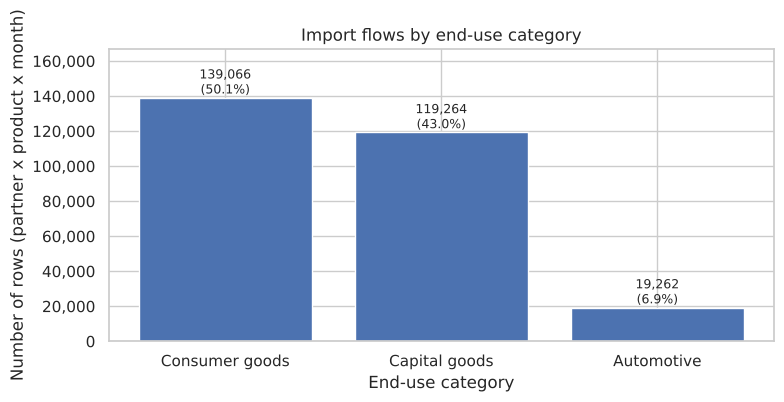

Share of total import DOLLARS by category:


category
Automotive       19.4000
Capital goods    45.6000
Consumer goods   35.0000
Name: import_value_usd, dtype: float64

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
c, p = bar_with_pct(df["category"], "Import flows by end-use category", "End-use category",
                    order=["Consumer goods", "Capital goods", "Automotive"], ax=ax)
plt.tight_layout(); plt.show()
print("Share of total import DOLLARS by category:")
(df.groupby("category")[TARGET].sum() / df[TARGET].sum() * 100).round(1)

**Category.** Consumer goods is the most common category with 139,066 rows (50.1%), then capital goods with 119,264 (43.0%), and automotive is far behind with 19,262 (6.9%). Consumer goods are on top because that category has the most distinct end-use codes (apparel, toys, furniture, phones and so on) and almost every country ships some of them. Automotive is the least common because few countries make cars and parts, so the category has fewer partner and product combinations.

Row counts are not dollars though. In dollars capital goods is the biggest (45.6% of total import value), consumer goods is 35.0% and automotive is 19.4%. So automotive has only 6.9% of the rows but almost a fifth of the money, meaning each automotive flow is large on average. We check this with a boxplot in 1.4.

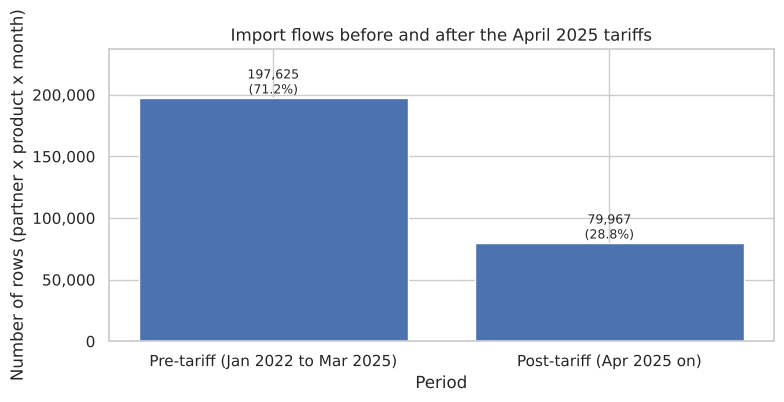

Months in each period: {'Post-tariff (Apr 2025 on)': 16, 'Pre-tariff (Jan 2022 to Mar 2025)': 39}
Average rows per month: {'Post-tariff (Apr 2025 on)': 4998.0, 'Pre-tariff (Jan 2022 to Mar 2025)': 5067.0}


In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
bar_with_pct(df["period"], "Import flows before and after the April 2025 tariffs", "Period",
             order=["Pre-tariff (Jan 2022 to Mar 2025)", "Post-tariff (Apr 2025 on)"], ax=ax)
plt.tight_layout(); plt.show()
print("Months in each period:", df.groupby("period")["month"].nunique().to_dict())
print("Average rows per month:", (df.groupby("period").size() / df.groupby("period")["month"].nunique()).round(0).to_dict())

**Period.** 197,625 rows (71.2%) are pre-tariff and 79,967 (28.8%) are post-tariff. The split is uneven only because the pre period covers 39 months and the post period 16 months. Per month the counts are almost the same: 5,067 rows per month before vs 4,998 after. So the number of partner and product combinations trading with the US barely changed after April 2025 (down about 1.4%). If the tariffs had a big effect, it shows up in how much was traded and what was paid, not in whether trade happened at all.

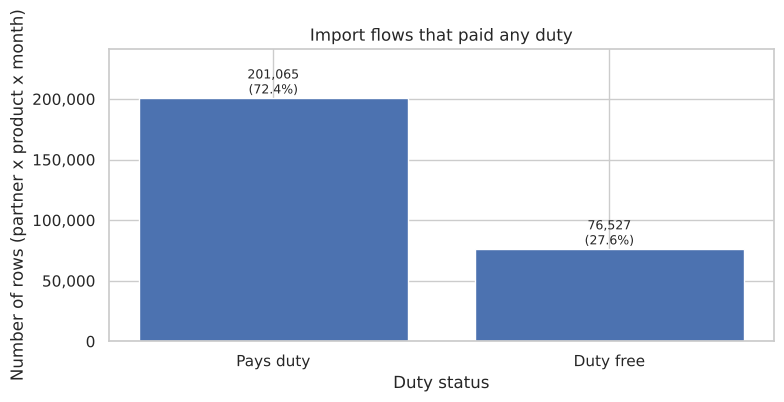

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
bar_with_pct(df["pays_duty"], "Import flows that paid any duty", "Duty status", order=["Pays duty", "Duty free"], ax=ax)
plt.tight_layout(); plt.show()

**Duty status.** 201,065 flows (72.4%) paid some duty and 76,527 (27.6%) were duty free. Paying duty is the normal case. The 27.6% duty free share is still large, and it comes from free trade agreements (most Canada and Mexico trade under USMCA) and from products with zero tariff lines. The next two charts split this by category and by period.

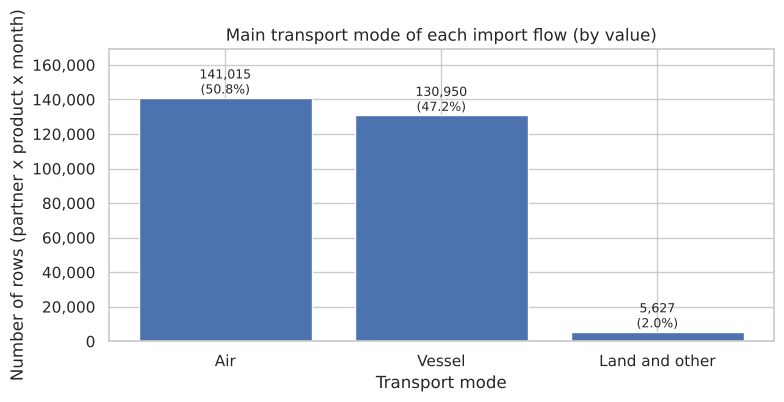

Share of import DOLLARS by main mode:


main_mode
Air              53.1000
Land and other    0.5000
Vessel           46.4000
Name: import_value_usd, dtype: float64

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
bar_with_pct(df["main_mode"], "Main transport mode of each import flow (by value)", "Transport mode",
             order=["Air", "Vessel", "Land and other"], ax=ax)
plt.tight_layout(); plt.show()
print("Share of import DOLLARS by main mode:")
(df.groupby("main_mode")[TARGET].sum() / df[TARGET].sum() * 100).round(1)

**Transport mode.** Air is the main mode for 141,015 flows (50.8%), vessel for 130,950 (47.2%), and land and other for only 5,627 (2.0%). By dollars it is air 53.1%, vessel 46.4% and land 0.5%. Land looks tiny here, which surprised us at first, but it is because the Census end-use endpoint does not report truck and rail values separately. Canada and Mexico trade mostly by truck, so for those flows "land and other" only wins when there is no air or vessel value at all. We note this as a limit of the data rather than a real finding about land shipping.

pays_duty,Duty free,Pays duty
category,,
Automotive,1945,17317
Capital goods,41431,77833
Consumer goods,33151,105915


pays_duty,Duty free,Pays duty
category,,
Automotive,10.1000,89.9000
Capital goods,34.7000,65.3000
Consumer goods,23.8000,76.2000


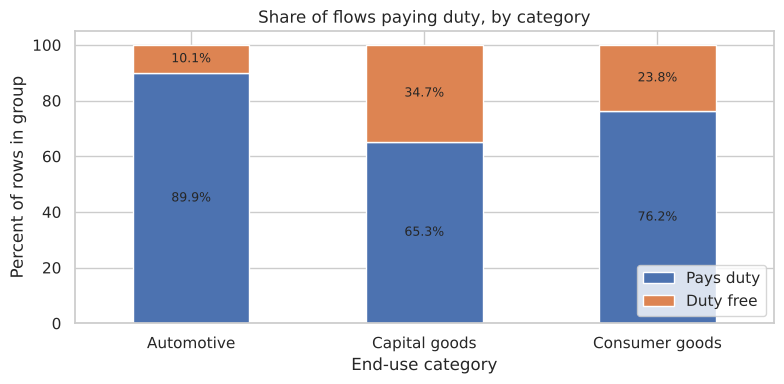

In [8]:
def stacked_duty(by, order, title, xlabel):
    ct = pd.crosstab(df[by], df["pays_duty"]).reindex(order)
    ct_pct = pd.crosstab(df[by], df["pays_duty"], normalize="index").reindex(order) * 100
    display(ct); display(ct_pct.round(1))
    ax = ct_pct[["Pays duty", "Duty free"]].plot(kind="bar", stacked=True, figsize=(8, 4), rot=0)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.1f%%", label_type="center", fontsize=9)
    ax.set_title(title); ax.set_xlabel(xlabel)
    ax.set_ylabel("Percent of rows in group"); ax.legend(title="", loc="lower right")
    plt.tight_layout(); plt.show()

stacked_duty("category", ["Automotive", "Capital goods", "Consumer goods"],
             "Share of flows paying duty, by category", "End-use category")

**Duty status by category.** 89.9% of automotive flows paid duty, compared to 76.2% of consumer goods and 65.3% of capital goods. Capital goods have the biggest duty-free share (34.7%), which fits with machinery and computer parts often having zero or low tariff lines. Automotive is almost always taxed, which is consistent with the Section 232 auto tariffs. This difference is what we formally test in section 2.3 (two-proportion z-test).

pays_duty,Duty free,Pays duty
period,,
Pre-tariff (Jan 2022 to Mar 2025),71042,126583
Post-tariff (Apr 2025 on),5485,74482


pays_duty,Duty free,Pays duty
period,,
Pre-tariff (Jan 2022 to Mar 2025),35.9000,64.1000
Post-tariff (Apr 2025 on),6.9000,93.1000


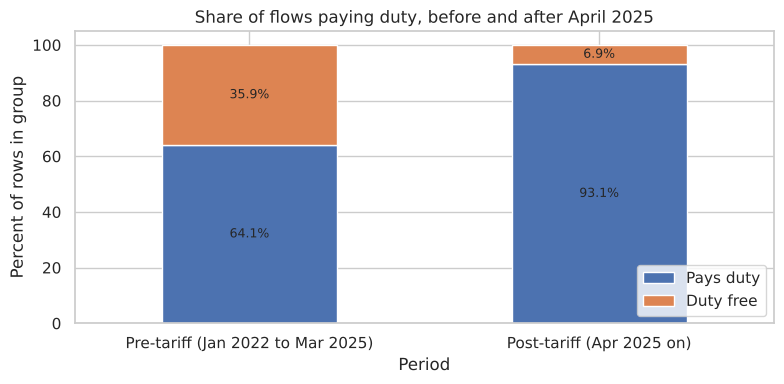

In [9]:
stacked_duty("period", ["Pre-tariff (Jan 2022 to Mar 2025)", "Post-tariff (Apr 2025 on)"],
             "Share of flows paying duty, before and after April 2025", "Period")

**Duty status by period.** Before April 2025, 64.1% of flows paid duty (126,583 of 197,625). After April 2025 it is 93.1% (74,482 of 79,967). The duty-free share fell from 35.9% to 6.9%. This is the clearest picture of the tariff policy in the categorical data: most of the products that used to come in free started paying something. We test this association with a chi-square test in section 2.4.

## 1.3 Histograms of continuous variables

All histograms use the original, untransformed columns. Because the dollar columns are so skewed, each variable gets two panels: the full range on the left (which is honest but mostly one tall bar) and the same data cut at the 95th percentile on the right so the shape of the bulk of the data is visible. The table after the charts holds the numbers we refer to.

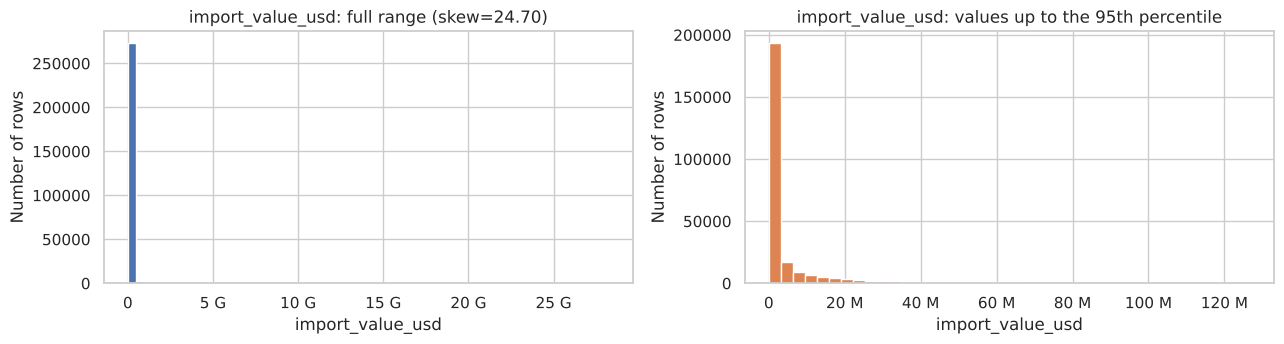

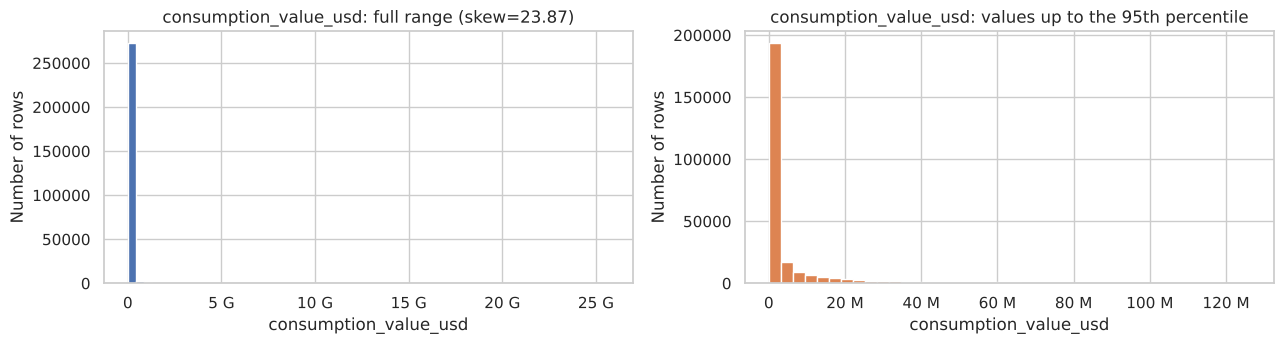

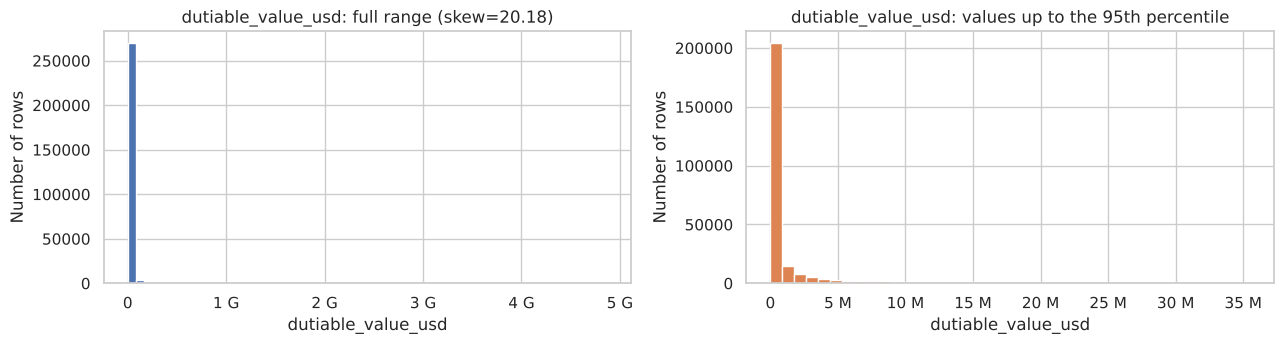

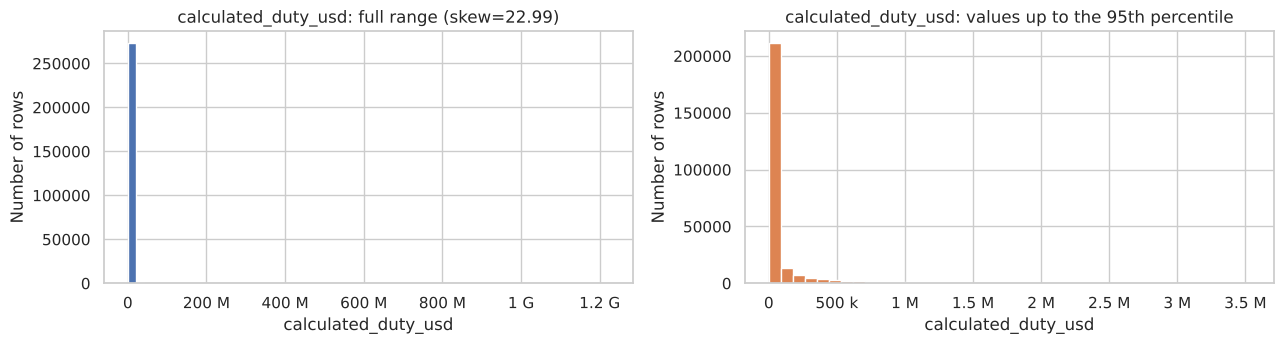

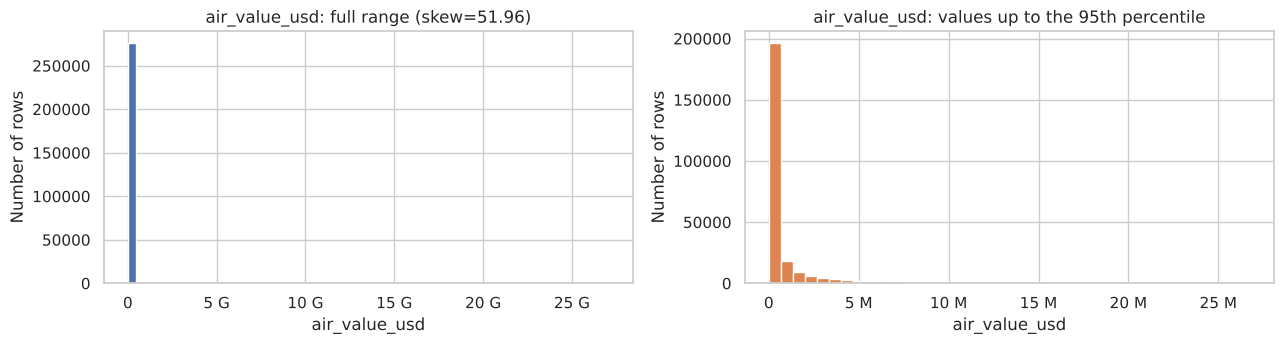

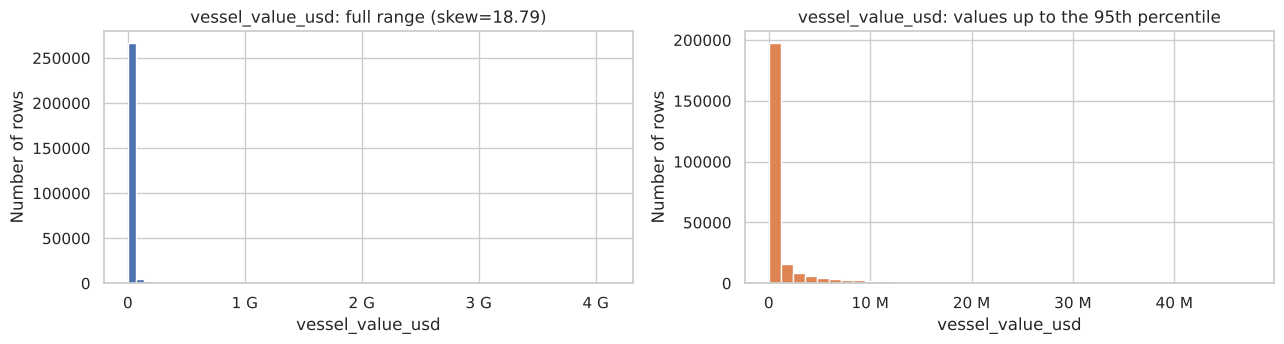

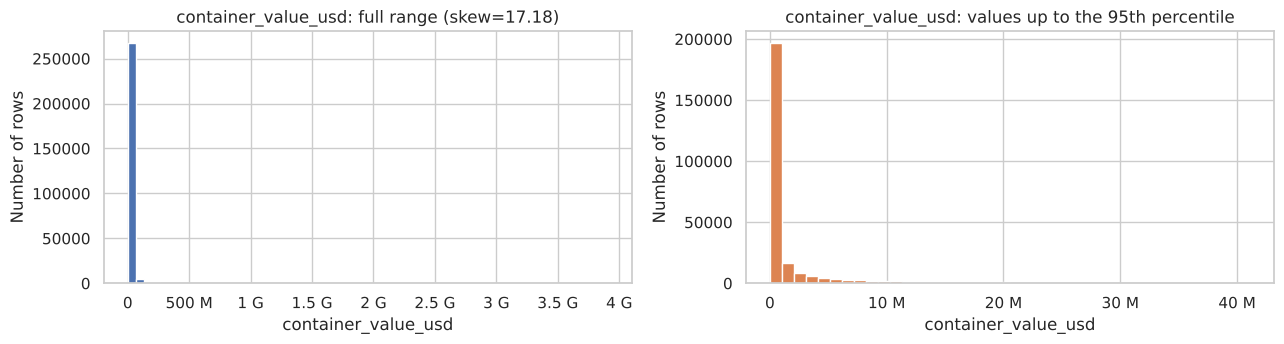

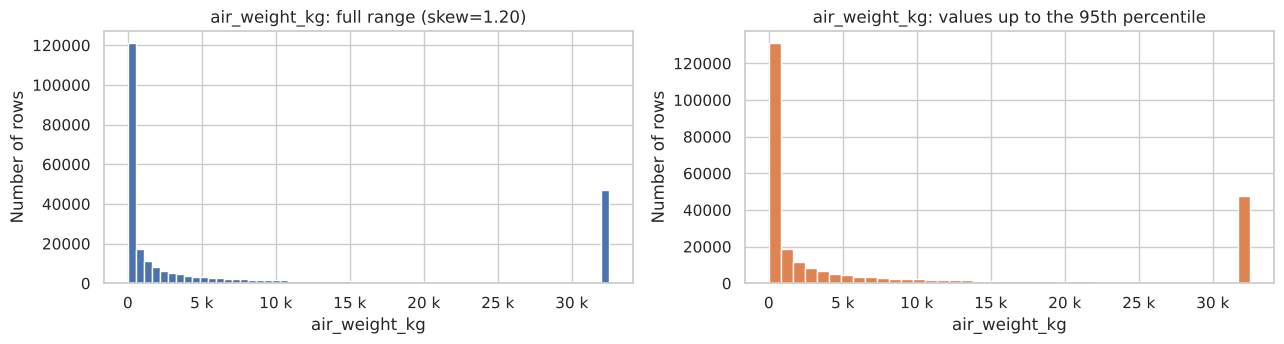

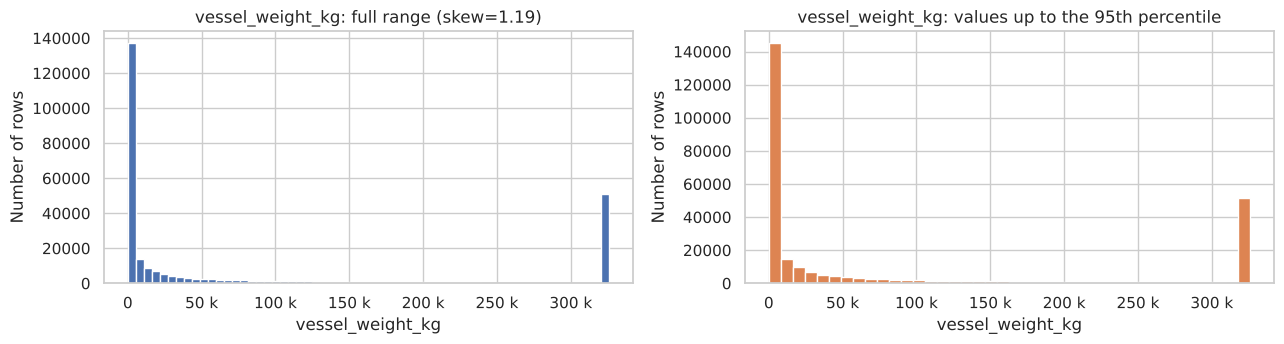

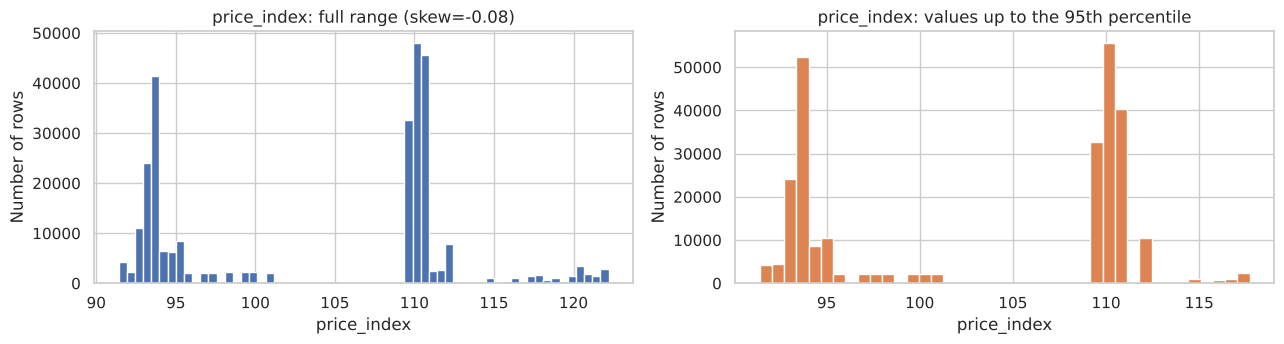

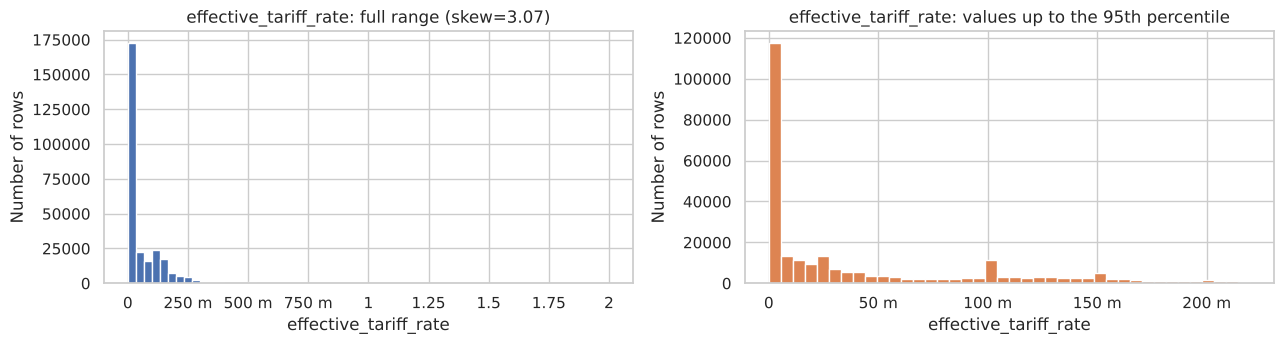

,skew,share of zeros %,mode bin (zoomed),median,5th pct,95th pct,max
column,,,,,,,
import_value_usd,24.6994,0.2781,"0.00 to 3,168,062.35","452,325","2,703","126,722,669","28,248,952,016"
consumption_value_usd,23.8736,0.3444,"0.00 to 3,156,796.60","449,714","2,681","126,276,886","25,693,269,167"
dutiable_value_usd,20.1838,27.2490,"0.00 to 887,557.32","46,238",0.0000,"35,504,889","4,872,319,463"
calculated_duty_usd,22.9893,27.5682,"0.00 to 88,332.18","3,048",0.0000,"3,533,455","1,223,453,165"
air_value_usd,51.9594,13.1567,"0.00 to 668,986.57","87,042",0.0000,"26,760,075","27,081,323,797"
vessel_value_usd,18.7868,30.4767,"0.00 to 1,186,560.43","95,144",0.0000,"47,463,029","4,113,840,106"
container_value_usd,17.1778,31.8817,"0.00 to 1,027,602.28","83,304",0.0000,"41,105,156","3,907,205,240"
air_weight_kg,1.2017,13.1567,0.00 to 812.75,"1,092",0.0000,"32,510","32,510"
vessel_weight_kg,1.1919,30.4767,"0.00 to 8,145.44","5,908",0.0000,"325,818","325,818"


In [10]:
hist_rows = []
for c in CONT:
    s = df[c]
    p95 = s.quantile(0.95)
    zoom = s[s <= p95]
    counts, edges = np.histogram(zoom, bins=40)
    k = counts.argmax()
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
    axes[0].hist(s, bins=60, color=sns.color_palette("deep")[0])
    axes[0].set_title(f"{c}: full range (skew={s.skew():.2f})")
    axes[1].hist(zoom, bins=40, color=sns.color_palette("deep")[1])
    axes[1].set_title(f"{c}: values up to the 95th percentile")
    for ax in axes:
        ax.set_xlabel(c); ax.set_ylabel("Number of rows")
        ax.xaxis.set_major_formatter(mtick.EngFormatter())
    plt.tight_layout(); plt.show()
    hist_rows.append({"column": c, "skew": s.skew(), "share of zeros %": (s == 0).mean() * 100,
                      "mode bin (zoomed)": f"{edges[k]:,.2f} to {edges[k + 1]:,.2f}",
                      "median": s.median(), "5th pct": s.quantile(0.05), "95th pct": p95, "max": s.max()})
hist_summary = pd.DataFrame(hist_rows).set_index("column")
hist_summary

**Reading each distribution**

- **`import_value_usd`.** Extremely right-skewed (skew 24.70). The full-range panel is one bar at 0 because the x-axis has to reach \$28.25B. In the zoomed panel the mode is the first bin (\$0 to \$3.17M) and the counts drop quickly after that. Most flows sit between \$2,703 (5th percentile) and \$126.7M (95th percentile). Only 0.28% are exactly zero. The shape tells us US imports are a long tail: lots of small partner and product pairs and a handful of giant ones.
- **`consumption_value_usd`.** Almost the same picture as the target (skew 23.87, median \$449,714, mode bin \$0 to \$3.16M). Not surprising since it is the same goods valued at the point they enter consumption. We come back to this in 1.6.
- **`dutiable_value_usd`.** Right-skewed (20.18) with a big spike at exactly 0: 27.2% of rows have no dutiable value. That spike is a cluster at the boundary, not a gap. It is the duty-free trade from 1.2.
- **`calculated_duty_usd`.** Same story: skew 22.99 and 27.6% zeros. Among the rest, most duty bills are small (median \$3,048, 95th percentile \$3.53M) and the mode bin is \$0 to \$88,332.
- **`air_value_usd`.** The most skewed column (51.96). 13.2% of rows have no air value. The mode bin is \$0 to \$668,987 and the 95th percentile is \$26.8M. A few air flows are bigger than anything shipped by sea, which is unusual and points to high-value, low-weight goods like semiconductors.
- **`vessel_value_usd` and `container_value_usd`.** Both right-skewed (18.79 and 17.18) with large zero spikes (30.5% and 31.9%). Container value is a part of vessel value, so its histogram looks like a slightly smaller copy.
- **`air_weight_kg` and `vessel_weight_kg`.** Right-skewed (about 1.2), with a pile-up at 0 (13.2% and 30.5%) and an unexpected spike at the right edge. That edge spike sits at exactly 32,510 kg and 325,818 kg, which are the D2 95th percentile caps. So the spike is something we created on purpose in D2, not something real in trade. The mode bins are 0 to 813 kg and 0 to 8,145 kg.
- **`price_index`.** This is the odd one. It is not smooth at all: it is multimodal, with three separate clusters and an empty gap between about 101 and 109. Each cluster is one BLS series: capital goods sits between 91.4 and 101.0, consumer goods between 109.4 and 112.3 (this is the tall mode at 109.8 to 110.5, since consumer goods has the most rows), and automotive between 114.5 and 122.2. Each series moves slowly over the 55 months, so the "distribution" is really three narrow bands. That tells an analyst the price index mostly encodes the category, and only a small part of its variation is change over time. 5th to 95th percentile is 92.9 to 117.7.
- **`effective_tariff_rate`.** Right-skewed (3.07). 27.6% of rows are exactly 0 (duty free) and the mode bin is 0% to 1%. The median is 1.49% and the 95th percentile is 22.0%. There is a long thin tail up to 200%, which comes from the 35 small rows explained in 1.1. Before any model, this tells us the tariff rate is really two things mixed together: a "pays or not" switch and a rate for those that pay.

## 1.4 Boxplots

### Single-variable boxplots
Every continuous variable that showed skew or an odd shape in 1.3 gets a boxplot. The y-axis is capped at the 95th percentile (or the upper whisker if that is higher), otherwise the box would be a flat line at the bottom of the chart.

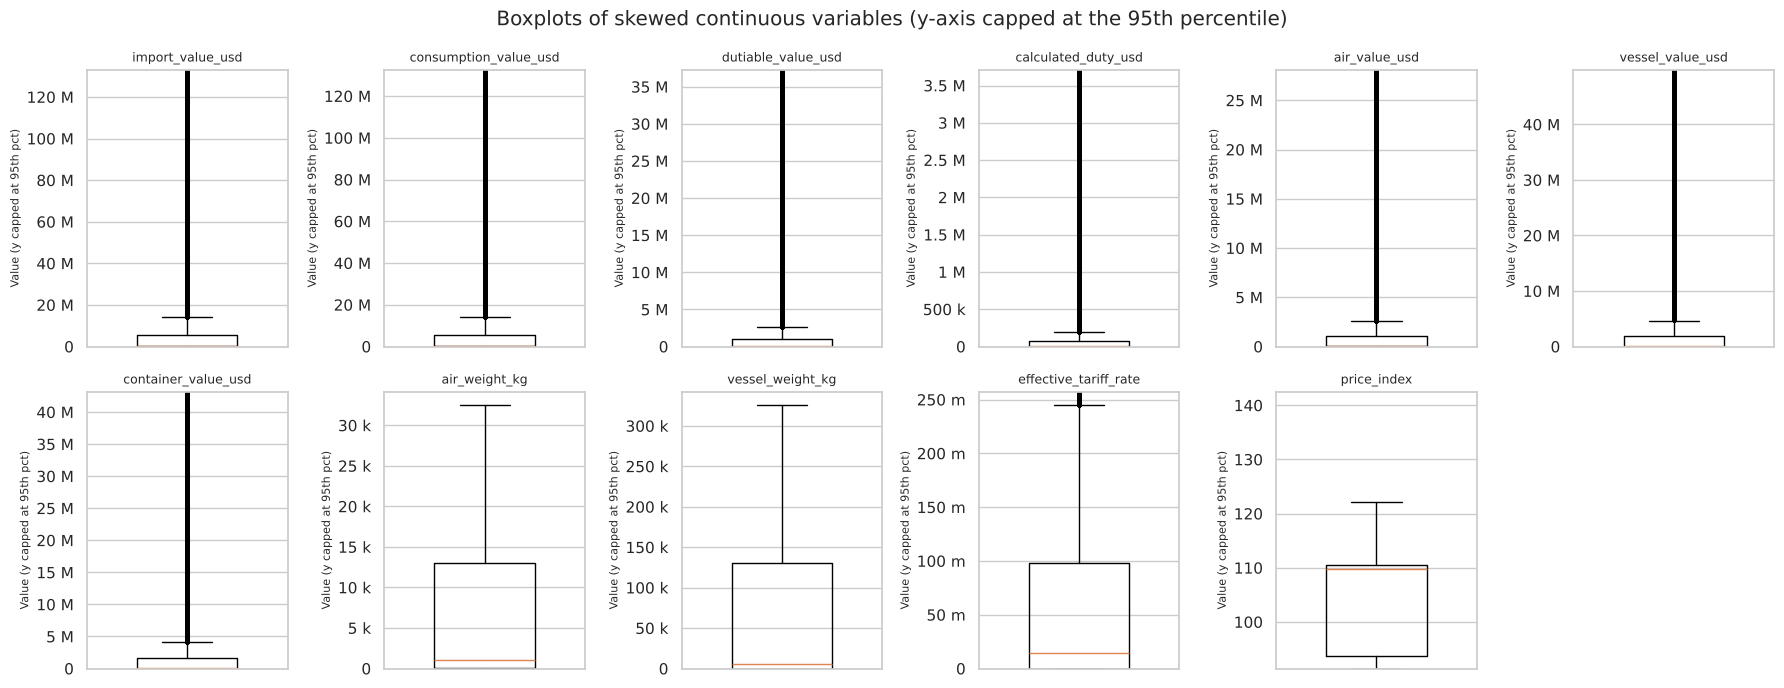

,median,Q1,Q3,outlier rows,outlier %
column,,,,,
import_value_usd,"452,325","33,675","5,713,393",48270,17.3888
consumption_value_usd,"449,714","33,419","5,663,086",48340,17.4140
dutiable_value_usd,"46,238",0.0000,"1,060,732",50540,18.2066
calculated_duty_usd,"3,048",0.0000,"75,362",51883,18.6904
air_value_usd,"87,042","6,111","1,042,203",48723,17.5520
vessel_value_usd,"95,144",0.0000,"1,875,002",50000,18.0120
container_value_usd,"83,304",0.0000,"1,656,024",49678,17.8960
air_weight_kg,"1,092",35.0000,"13,025",0,0.0000
vessel_weight_kg,"5,908",0.0000,"130,329",0,0.0000


In [11]:
SKEWED = [c for c in CONT if abs(df[c].skew()) > 0.5] + ["price_index"]   # price_index added for its odd shape
fig, axes = plt.subplots(2, 6, figsize=(18, 7))
box_rows = []
for ax, c in zip(axes.flat, SKEWED):
    s = df[c]
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
    ax.boxplot(s, widths=0.5, flierprops={"markersize": 2, "alpha": 0.3})
    ax.set_ylim(s.min(), max(s.quantile(0.95), q3 + 1.5 * iqr) * 1.05)
    ax.set_title(c, fontsize=9); ax.set_xticks([]); ax.set_ylabel("Value (y capped at 95th pct)", fontsize=8)
    ax.yaxis.set_major_formatter(mtick.EngFormatter())
    box_rows.append({"column": c, "median": s.median(), "Q1": q1, "Q3": q3, "outlier rows": n_out,
                     "outlier %": n_out / len(s) * 100})
for ax in axes.flat[len(SKEWED):]:
    ax.axis("off")
fig.suptitle("Boxplots of skewed continuous variables (y-axis capped at the 95th percentile)")
plt.tight_layout(); plt.show()
pd.DataFrame(box_rows).set_index("column")

**Note on the y-axis:** every panel above is capped at the 95th percentile, so the outlier dots you see are only the ones below that cap. The counts in the table are for the full column.

The dollar columns all have a very short box near zero and a long column of outlier dots. Using the 1.5 x IQR rule, 48,270 rows (17.4%) of `import_value_usd` are outliers, and the duty, dutiable, air, vessel and container columns are all between 17.4% and 18.7%. When almost a fifth of the data is "outliers", the rule is really telling us the distribution has a heavy tail, not that the points are errors, which is why D2 kept them and only flagged them. The weight columns show 0 outliers because of the D2 cap, and `price_index` has none because it is bounded. `effective_tariff_rate` has 10,771 outlier rows (3.9%) above a Q3 of 9.8%.

### Grouped boxplots
These compare a continuous variable across groups that matter for our question: category and tariff period.

In [12]:
def grouped_box(col, by, order, title, ylabel, pct=False):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    sns.boxplot(data=df, x=by, y=col, order=order, ax=ax, fliersize=1.5)
    cap = df[col].quantile(0.95)
    ax.set_ylim(df[col].min(), cap * 1.05)
    ax.set_title(title); ax.set_xlabel(by.replace("_", " ").title()); ax.set_ylabel(ylabel)
    if pct:
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    else:
        ax.yaxis.set_major_formatter(mtick.EngFormatter())
    plt.tight_layout(); plt.show()
    rows = []
    for g in order:
        s = df.loc[df[by] == g, col]
        q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
        n_out = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
        rows.append({by: g, "rows": len(s), "median": s.median(), "Q1": q1, "Q3": q3, "IQR": iqr,
                     "outlier dots (above/below 1.5 IQR)": n_out})
    return pd.DataFrame(rows).set_index(by)

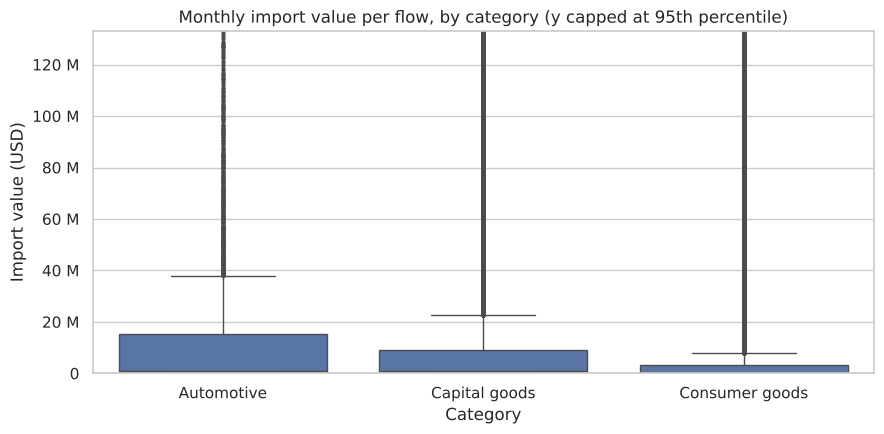

,rows,median,Q1,Q3,IQR,outlier dots (above/below 1.5 IQR)
category,,,,,,
Automotive,19262,"917,849","53,617","15,203,981","15,150,364",3205
Capital goods,119264,"726,499","44,140","9,039,748","8,995,608",19498
Consumer goods,139066,"294,700","25,689","3,185,240","3,159,550",24320


In [13]:
grouped_box(TARGET, "category", ["Automotive", "Capital goods", "Consumer goods"],
            "Monthly import value per flow, by category (y capped at 95th percentile)", "Import value (USD)")

*Y-axis capped at the 95th percentile of `import_value_usd` (\$126.7M) so the boxes are readable. Outlier counts in the table are for the full data.*

**Import value by category.** Automotive has the highest median at \$917,849, then capital goods at \$726,499, and consumer goods is much lower at \$294,700. The spread follows the same order: the automotive IQR is \$15.15M, capital goods \$9.00M and consumer goods only \$3.16M. Outlier dots: 3,205 automotive, 19,498 capital goods, 24,320 consumer goods. So consumer goods has the most flows but the smallest typical flow, and automotive has the fewest flows but the biggest typical flow, which matches what we saw in the dollar shares in 1.2. For our target this means category matters a lot: the same partner can have very different import values depending on what it ships.

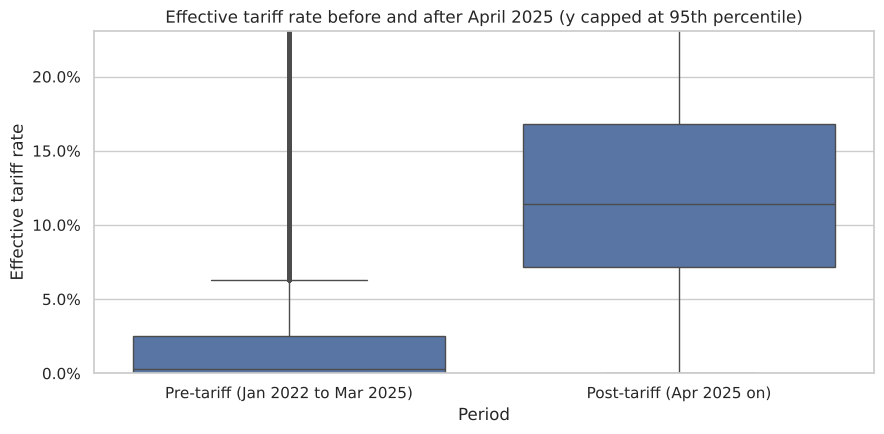

,rows,median,Q1,Q3,IQR,outlier dots (above/below 1.5 IQR)
period,,,,,,
Pre-tariff (Jan 2022 to Mar 2025),197625,0.0026,0.0000,0.0251,0.0251,22290
Post-tariff (Apr 2025 on),79967,0.1139,0.0716,0.1683,0.0968,4621


In [14]:
grouped_box("effective_tariff_rate", "period", ["Pre-tariff (Jan 2022 to Mar 2025)", "Post-tariff (Apr 2025 on)"],
            "Effective tariff rate before and after April 2025 (y capped at 95th percentile)", "Effective tariff rate", pct=True)

*Y-axis capped at the 95th percentile of `effective_tariff_rate` (22.0%).*

**Effective tariff rate by period.** This is the biggest change in the whole EDA. The pre-tariff median is 0.26% with an IQR of 2.51% (Q1 0%, Q3 2.51%), so before April 2025 most flows paid almost nothing. After April 2025 the median jumps to 11.39% and the IQR widens to 9.68% (Q1 7.16%, Q3 16.83%). The whole post box sits above the top of the pre box. There are 22,290 outlier dots in the pre period (the few products that already paid high rates stand out because the box is so low) and 4,621 in the post period. We test the difference in means formally in 2.3.

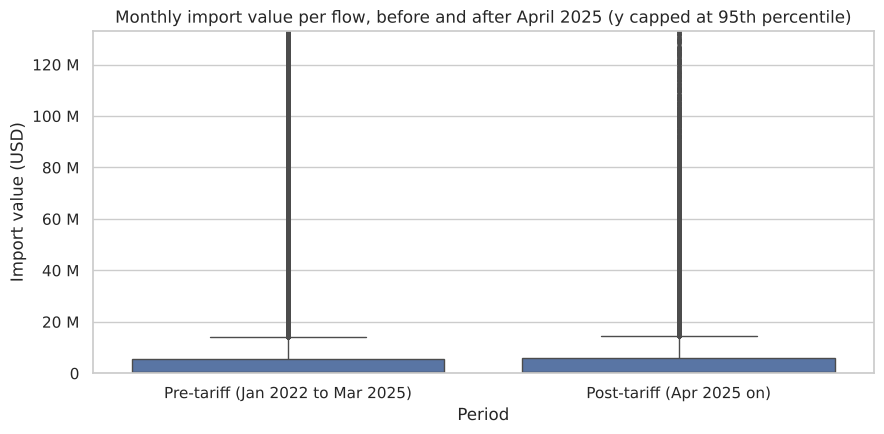

,rows,median,Q1,Q3,IQR,outlier dots (above/below 1.5 IQR)
period,,,,,,
Pre-tariff (Jan 2022 to Mar 2025),197625,"452,939","33,829","5,700,880","5,667,051",34332
Post-tariff (Apr 2025 on),79967,"450,827","33,237","5,752,882","5,719,646",13923


In [15]:
grouped_box(TARGET, "period", ["Pre-tariff (Jan 2022 to Mar 2025)", "Post-tariff (Apr 2025 on)"],
            "Monthly import value per flow, before and after April 2025 (y capped at 95th percentile)", "Import value (USD)")

*Y-axis capped at the 95th percentile of `import_value_usd`.*

**Import value by period.** Here the two boxes look almost identical. The median is \$452,939 before and \$450,827 after, and the IQR is \$5.67M vs \$5.72M. Outlier dots: 34,332 pre, 13,923 post. So even though the tariff rate jumped (previous chart), the typical flow did not shrink. Whatever changed after the tariffs happened in the biggest flows and in which countries they came from, not in the typical row. This is why the dashboard in Part 3 looks at partner countries, and why we did not run a t-test on mean import value by period: the boxplot gave us no visible difference to formalise.

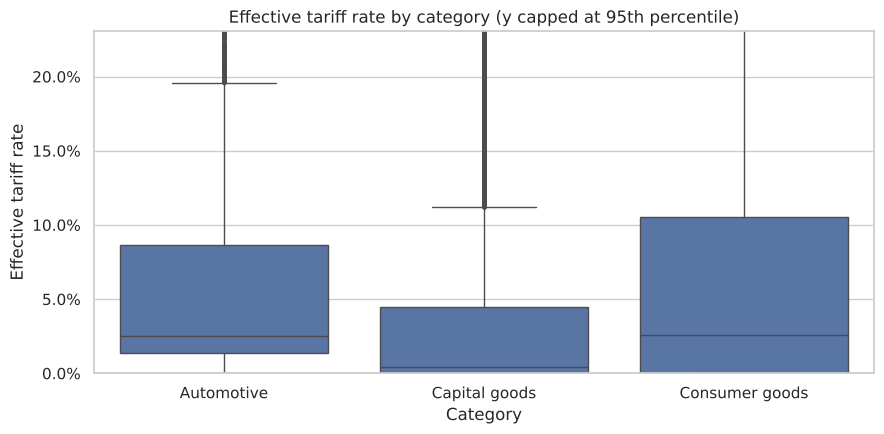

,rows,median,Q1,Q3,IQR,outlier dots (above/below 1.5 IQR)
category,,,,,,
Automotive,19262,0.0250,0.0135,0.0864,0.0729,2415
Capital goods,119264,0.0041,0.0000,0.0449,0.0449,16326
Consumer goods,139066,0.0259,0.0001,0.1055,0.1055,4015


In [16]:
grouped_box("effective_tariff_rate", "category", ["Automotive", "Capital goods", "Consumer goods"],
            "Effective tariff rate by category (y capped at 95th percentile)", "Effective tariff rate", pct=True)

*Y-axis capped at the 95th percentile of `effective_tariff_rate`.*

**Effective tariff rate by category.** Consumer goods (median 2.59%, IQR 10.55%) and automotive (median 2.50%, IQR 7.29%) pay much more than capital goods (median 0.41%, IQR 4.49%). Outlier dots: 2,415 automotive, 16,326 capital goods, 4,015 consumer goods. Capital goods has the most outliers because its box is so low that any taxed machine looks unusual. Put together with the previous boxplot, the duty burden depends on both what you import and when.

## 1.6 Correlation heatmap and feature selection

*Note: we do 1.6 before 1.5 because the scatter plots in 1.5 are chosen from the pairs that the heatmap flags.*

The target `import_value_usd` is removed from the feature list **before** the correlation matrix is computed, so the heatmap only shows relationships between independent features.

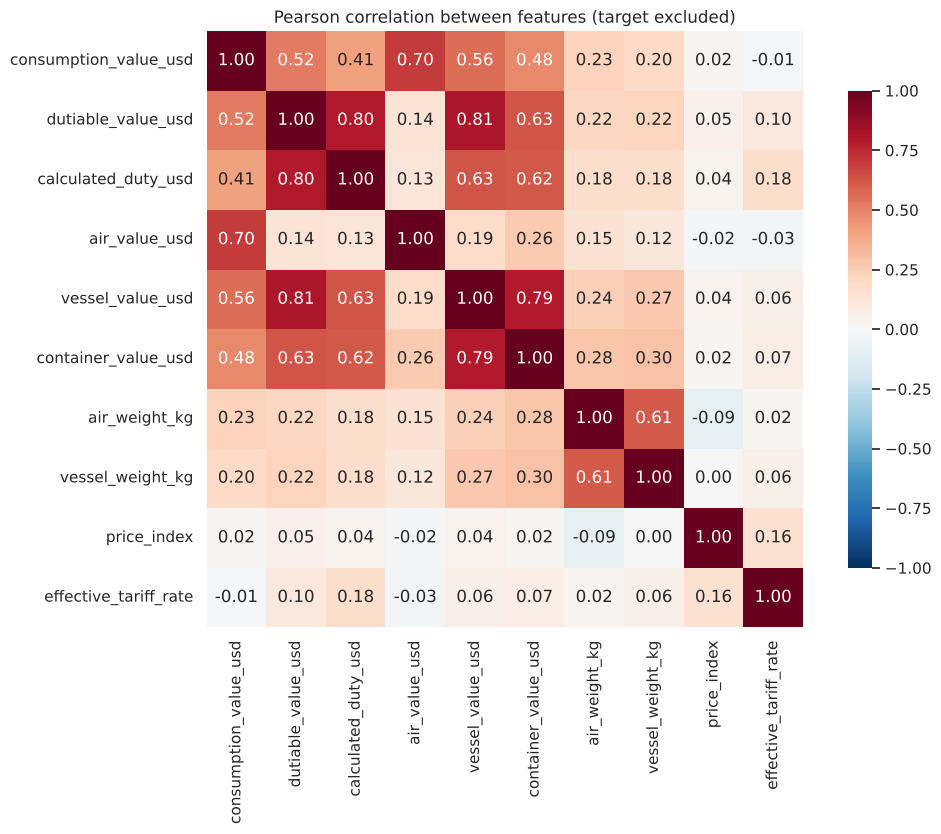

,feature A,feature B,r
2,dutiable_value_usd,vessel_value_usd,0.8145
1,dutiable_value_usd,calculated_duty_usd,0.7979
3,vessel_value_usd,container_value_usd,0.7930
0,consumption_value_usd,air_value_usd,0.7020


In [17]:
FEATURES = [c for c in CONT if c != TARGET]          # target removed BEFORE the matrix is computed
corr = df[FEATURES].corr(method="pearson")
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Pearson correlation between features (target excluded)")
plt.tight_layout(); plt.show()

high = [(a, b, corr.loc[a, b]) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:] if abs(corr.loc[a, b]) > 0.7]
pd.DataFrame(high, columns=["feature A", "feature B", "r"]).sort_values("r", key=abs, ascending=False)

**Pairs with |r| > 0.7.** Four pairs cross the line:

| Pair | r |
|---|---|
| dutiable_value_usd and vessel_value_usd | 0.81 |
| dutiable_value_usd and calculated_duty_usd | 0.80 |
| vessel_value_usd and container_value_usd | 0.79 |
| consumption_value_usd and air_value_usd | 0.70 (0.7020) |

All four make sense from how the data is built. Duty is calculated on the dutiable value, so those two have to move together. Most taxed goods come by ship, so dutiable and vessel value move together. Container value is a part of vessel value. And consumption value is basically the total, so it overlaps with air value, the biggest single mode. The weak spots are also useful: `price_index` and `effective_tariff_rate` have |r| below 0.2 with everything, so they bring information none of the dollar columns have.

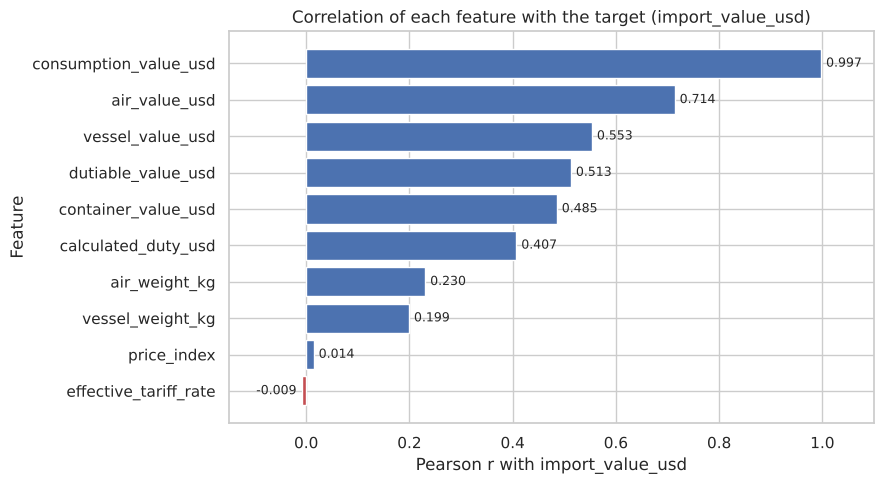

,r with target
consumption_value_usd,0.9972
air_value_usd,0.7135
vessel_value_usd,0.5532
dutiable_value_usd,0.5125
container_value_usd,0.4851
calculated_duty_usd,0.4067
air_weight_kg,0.2302
vessel_weight_kg,0.1988
price_index,0.0142
effective_tariff_rate,-0.0087


In [18]:
target_corr = df[FEATURES].corrwith(df[TARGET]).sort_values(key=abs)
fig, ax = plt.subplots(figsize=(9, 5))
colors = [sns.color_palette("deep")[3] if v < 0 else sns.color_palette("deep")[0] for v in target_corr]
ax.barh(target_corr.index, target_corr.values, color=colors)
for i, v in enumerate(target_corr.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:.3f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.set_title(f"Correlation of each feature with the target ({TARGET})")
ax.set_xlabel("Pearson r with import_value_usd"); ax.set_ylabel("Feature"); ax.set_xlim(-0.15, 1.1)
plt.tight_layout(); plt.show()
target_corr.sort_values(key=abs, ascending=False).to_frame("r with target")

**Ranked correlation with the target.** `consumption_value_usd` is almost a copy of the target (r = 0.997). After that comes `air_value_usd` (0.714), `vessel_value_usd` (0.553), `dutiable_value_usd` (0.513), `container_value_usd` (0.485) and `calculated_duty_usd` (0.407). The weights are weak (0.230 and 0.199), and `price_index` (0.014) and `effective_tariff_rate` (-0.009) are essentially zero.

The near-zero r for the tariff rate does not mean tariffs are irrelevant. Pearson r only measures a straight-line relationship across all rows, and a \$300 flow and a \$3B flow can both pay 10%. The tariff effect we care about is a change over time and across countries, which is what Part 2 and the dashboard look at.

In [19]:
REMOVE = {
    "consumption_value_usd": "same shipment dollars as the target on a consumption basis (r = 0.997 with the target); keeping it would leak the answer",
    "dutiable_value_usd": "only the taxable base of the duty; calculated_duty_usd already carries the tariff signal we care about",
    "container_value_usd": "a subset of vessel_value_usd (containerised vessel shipments), so it repeats the vessel information",
}
display(pd.DataFrame.from_dict(REMOVE, orient="index", columns=["reason for removal"]))
FINAL_FEATURES = [c for c in FEATURES if c not in REMOVE]
left = df[FINAL_FEATURES].corr()
still_high = [(a, b, round(left.loc[a, b], 3)) for i, a in enumerate(FINAL_FEATURES) for b in FINAL_FEATURES[i + 1:] if abs(left.loc[a, b]) > 0.7]
print("Pairs above |0.7| after removal:", still_high)
print("Final feature list:", FINAL_FEATURES)

,reason for removal
consumption_value_usd,same shipment dollars as the target on a consu...
dutiable_value_usd,only the taxable base of the duty; calculated_...
container_value_usd,a subset of vessel_value_usd (containerised ve...


Pairs above |0.7| after removal: []
Final feature list: ['calculated_duty_usd', 'air_value_usd', 'vessel_value_usd', 'air_weight_kg', 'vessel_weight_kg', 'price_index', 'effective_tariff_rate']


**What we removed and why**

- **dutiable_value_usd vs vessel_value_usd (0.81) and dutiable_value_usd vs calculated_duty_usd (0.80): we removed `dutiable_value_usd`.** It is in two of the four high pairs, so dropping it fixes both at once. On domain grounds it is just the tax base, and `calculated_duty_usd` already carries the tariff signal our business question is about. Its correlation with the target (0.513) is also lower than vessel value (0.553), so we keep vessel value.
- **vessel_value_usd vs container_value_usd (0.79): we removed `container_value_usd`.** Container value is a subset of vessel value (container shipments are vessel shipments), so it repeats information. Vessel value also has the stronger link to the target (0.553 vs 0.485) and is easier to explain.
- **consumption_value_usd vs air_value_usd (0.70): we removed `consumption_value_usd`.** This is the one that matters most for Project 2. With r = 0.997 against the target it is the same dollars counted at a slightly different point, so keeping it would leak the answer into the model. `air_value_usd` stays because it is a real transport-mode feature.

After removal no pair is above 0.7. Final features for Project 2: `calculated_duty_usd`, `air_value_usd`, `vessel_value_usd`, `air_weight_kg`, `vessel_weight_kg`, `price_index`, `effective_tariff_rate` (plus the categorical columns category, period, pays_duty and main_mode).

## 1.5 Scatter plots of the flagged pairs

One scatter plot per pair from 1.6, each coloured by the target. We plot a random sample of 5,000 rows (random_state = 42) so the points do not all sit on top of each other, but the r in the titles is computed on all 277,592 rows.

Every pair is shown twice. The left panel is the original scale, as required. On its own it is not readable: one \$2B point stretches the axis and more than 95% of the rows end up squashed into the corner at 0. The right panel plots the **same untransformed values** on symlog axes (log scale with a linear section around 0 so the zero rows still show). We did this instead of using the D2 log columns because it keeps the real dollar labels on the axes, and it makes the actual pattern visible across all sizes of flow.

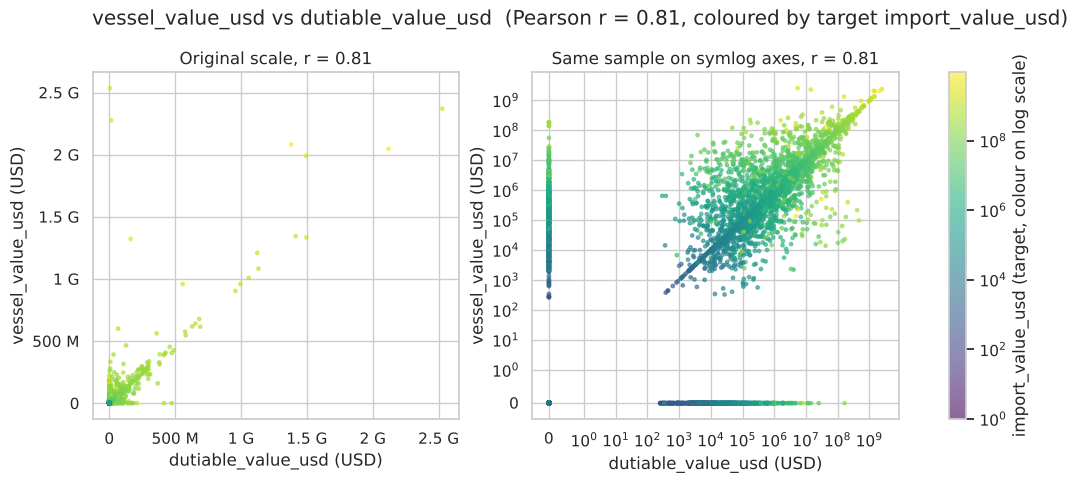

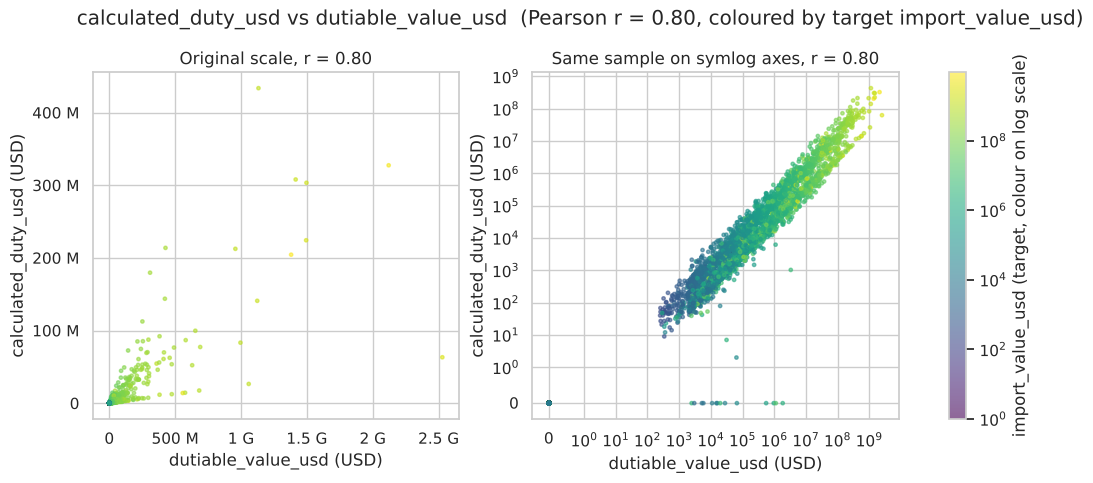

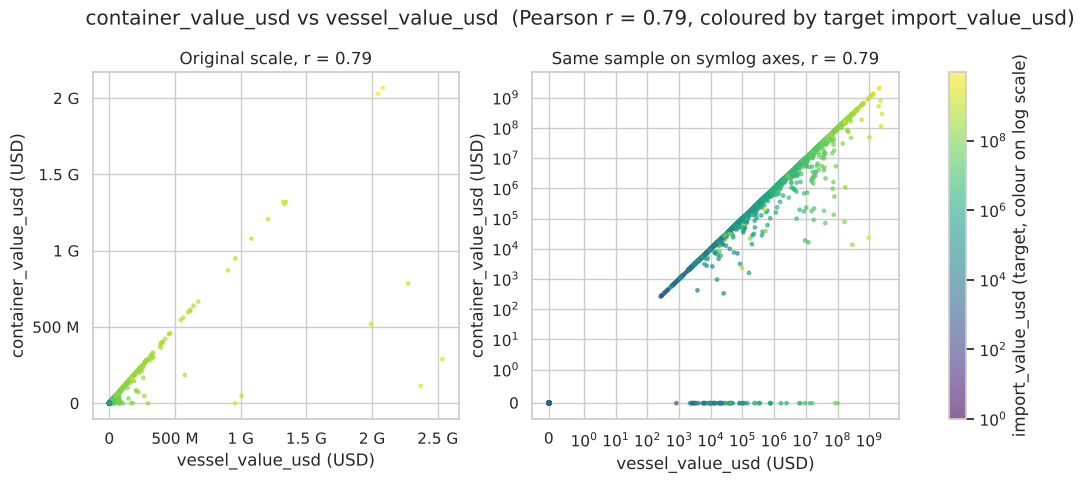

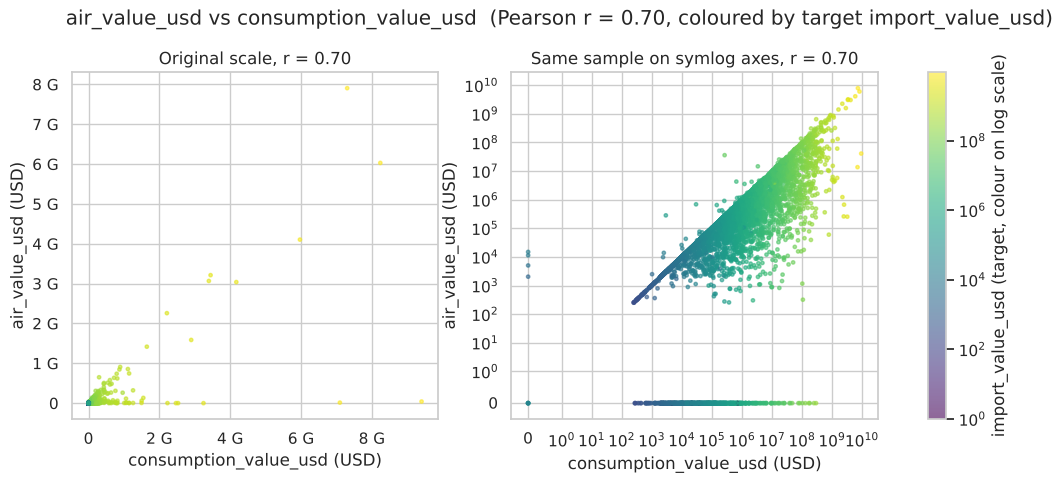

In [20]:
PAIRS = [("dutiable_value_usd", "vessel_value_usd"), ("dutiable_value_usd", "calculated_duty_usd"),
         ("vessel_value_usd", "container_value_usd"), ("consumption_value_usd", "air_value_usd")]
sample = df.sample(5000, random_state=42)
for x, y in PAIRS:
    r = df[x].corr(df[y])
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, logged in zip(axes, [False, True]):
        sc = ax.scatter(sample[x], sample[y], c=sample[TARGET].clip(lower=1), cmap="viridis",
                        norm=LogNorm(), s=6, alpha=0.6)
        if logged:
            ax.set_xscale("symlog", linthresh=1); ax.set_yscale("symlog", linthresh=1)
            ax.set_title(f"Same sample on symlog axes, r = {r:.2f}")
        else:
            ax.xaxis.set_major_formatter(mtick.EngFormatter()); ax.yaxis.set_major_formatter(mtick.EngFormatter())
            ax.set_title(f"Original scale, r = {r:.2f}")
        ax.set_xlabel(f"{x} (USD)"); ax.set_ylabel(f"{y} (USD)")
    fig.suptitle(f"{y} vs {x}  (Pearson r = {r:.2f}, coloured by target import_value_usd)", y=1.02)
    fig.colorbar(sc, ax=axes, label="import_value_usd (target, colour on log scale)")
    plt.show()

**dutiable_value_usd vs vessel_value_usd (r = 0.81).** Strong positive relationship. On the log panel most points sit in a wide band going up to the right: the more a partner ships by sea in a product, the more of it is dutiable. There is also a column of points at dutiable = 0 with plenty of vessel value, which is duty-free ocean freight. The colour goes from purple at the bottom left to yellow at the top right, so the biggest target values come from flows that are large on both axes.

**calculated_duty_usd vs dutiable_value_usd (r = 0.80).** Strong positive and very tight on the log panel. The points form a straight diagonal band, because duty is the dutiable value times a rate. The width of the band is the spread of tariff rates between products and countries. A few points sit at duty = 0 with dutiable value above 0, which are likely rows where the duty was waived or reported separately. The colour shows the target rises along the band, so a large duty bill means a large import flow, but the r of 0.407 with the target (1.6) says duty alone is a much weaker guide than the shipment values.

**container_value_usd vs vessel_value_usd (r = 0.79).** On the log panel there is a hard edge: almost no point is above the diagonal, because a container value can never be bigger than the vessel value it is part of. Most points are right on the line (all the ocean freight was containerised). The points below it are bulk or roll-on/roll-off cargo, like cars and big machinery. Colour again goes yellow at the top, so these two together track the target closely, which is why keeping both would be redundant.

**air_value_usd vs consumption_value_usd (r = 0.70).** The weakest of the four but still strong. The log panel shows a clear upper edge along the diagonal, where all of the flow came by air, with a fan of points below it, which are flows that partly or mostly came by sea. A handful of points sit just above the edge because air value is recorded on the general imports basis and consumption value on a slightly different one. There is also a long line at air = 0 for flows with no air freight at all. The yellow points (the largest target values) are near the top of the fan, so the biggest import flows are mostly air flows, which matches the 53.1% air share of import dollars from 1.2.

# Part 2: Statistical Inference

Every test answers a question that came out of Part 1, and every test uses α = 0.05.

**A note on sample size.** We have 277,592 rows, so even tiny differences come out as "significant". Several p-values are so small that Python cannot store them and they underflow to 0, so we print them as "< 1e-300". To keep the conclusions honest we also report an effect size (Cohen's d, Cohen's h or Cramér's V) and say in words whether the difference is big enough to matter for an importer, not just whether it is significant.

## 2.1 Confidence interval for a mean

**Question from the EDA:** the boxplot in 1.4 showed the effective tariff rate jumped after April 2025. What is the average rate an importer actually paid in the post-tariff period? This is central to the business question because it is the cost the procurement team has to plan for.

In [21]:
x = df.loc[df["period"] == "Post-tariff (Apr 2025 on)", "effective_tariff_rate"]
n = len(x); xbar = x.mean(); s = x.std(ddof=1); dof = n - 1
t_star = stats.t.ppf(0.975, dof)
se = s / np.sqrt(n); me = t_star * se
steps = pd.Series({"sample mean (x bar)": xbar, "standard deviation (s)": s, "sample size (n)": n,
                   "degrees of freedom (n - 1)": dof, "critical value t* (95%)": t_star,
                   "standard error (s / sqrt n)": se, "margin of error (t* x SE)": me,
                   "lower bound": xbar - me, "upper bound": xbar + me}, name="value")
display(steps.to_frame())
print(f"95% CI for the mean effective tariff rate after April 2025: {xbar - me:.4%} to {xbar + me:.4%}")

,value
sample mean (x bar),0.1334
standard deviation (s),0.1104
sample size (n),"79,967"
degrees of freedom (n - 1),"79,966"
critical value t* (95%),1.9600
standard error (s / sqrt n),0.0004
margin of error (t* x SE),0.0008
lower bound,0.1327
upper bound,0.1342


95% CI for the mean effective tariff rate after April 2025: 13.2659% to 13.4190%


**Steps:** x̄ = 0.1334, s = 0.1104, n = 79,967, df = 79,966, t* = 1.960 (with this many degrees of freedom the t value is the same as z to three decimals), SE = 0.1104 / √79,967 = 0.00039, margin of error = 1.960 × 0.00039 = 0.00077.

**Interval:** 13.27% to 13.42%.

**In plain words:** we are 95% confident that, after April 2025, a typical US import flow in these three categories paid on average between 13.3% and 13.4% of its value in duty. That is about 5.6 times the 2.38% average before the tariffs. The interval is very narrow because n is so large, so the uncertainty is about 0.08 of a percentage point.

## 2.2 Confidence interval for a proportion

**Question from the EDA:** the stacked bar in 1.2 showed that almost all post-tariff flows paid duty. What share of import flows now pays any duty at all?

In [22]:
post = df[df["period"] == "Post-tariff (Apr 2025 on)"]
n = len(post); successes = int((post["pays_duty"] == "Pays duty").sum()); p_hat = successes / n
z_star = stats.norm.ppf(0.975)
se = np.sqrt(p_hat * (1 - p_hat) / n); me = z_star * se
steps = pd.Series({"flows paying duty (x)": successes, "sample size (n)": n, "sample proportion (p hat)": p_hat,
                   "check n*p hat >= 10": n * p_hat, "check n*(1 - p hat) >= 10": n * (1 - p_hat),
                   "critical value z* (95%)": z_star, "standard error sqrt(p(1-p)/n)": se,
                   "margin of error (z* x SE)": me, "lower bound": p_hat - me, "upper bound": p_hat + me}, name="value")
display(steps.to_frame())
print(f"95% CI for the share of post-tariff import flows paying duty: {p_hat - me:.2%} to {p_hat + me:.2%}")

,value
flows paying duty (x),"74,482"
sample size (n),"79,967"
sample proportion (p hat),0.9314
check n*p hat >= 10,"74,482"
check n*(1 - p hat) >= 10,"5,485"
critical value z* (95%),1.9600
standard error sqrt(p(1-p)/n),0.0009
margin of error (z* x SE),0.0018
lower bound,0.9297
upper bound,0.9332


95% CI for the share of post-tariff import flows paying duty: 92.97% to 93.32%


**Steps:** x = 74,482 flows paying duty, n = 79,967, p̂ = 0.9314. The normal approximation is fine because n·p̂ = 74,482 and n·(1 − p̂) = 5,485 are both far above 10. z* = 1.960, SE = √(0.9314 × 0.0686 / 79,967) = 0.00089, margin of error = 0.0018.

**Interval:** 92.97% to 93.32%.

**What it tells us about the population:** after April 2025, between about 93.0% and 93.3% of all partner and product import flows pay some duty. Before the tariffs it was 64.1%. For an importer, that means "duty free" is now the rare exception (under 7% of flows), so it is no longer safe to assume a supplier's goods will come in tax free.

## 2.3 Hypothesis tests: two-group comparisons

### Test A: two-sample t-test (comparing means)
**Visual finding it formalises:** the grouped boxplot "Effective tariff rate before and after April 2025" in 1.4, where the post box sat completely above the pre box (median 0.26% vs 11.39%).

**Groups:** pre-tariff flows vs post-tariff flows. We use Welch's t-test (not the pooled version) because the two groups have very different spreads (IQR 2.51% vs 9.68%).

In [23]:
pre_rate = df.loc[df["period"] == "Pre-tariff (Jan 2022 to Mar 2025)", "effective_tariff_rate"]
post_rate = df.loc[df["period"] == "Post-tariff (Apr 2025 on)", "effective_tariff_rate"]
alpha = 0.05
t_stat, p_val = stats.ttest_ind(post_rate, pre_rate, equal_var=False)   # Welch: variances clearly differ
print("Step 1  H0: mean effective tariff rate after April 2025 = mean before")
print("        H1: the two means are different (two-sided)")
print("Step 2  alpha =", alpha)
print(f"Step 3  Welch t statistic = {t_stat:,.2f}   (pre mean {pre_rate.mean():.4f}, n={len(pre_rate):,};"
      f" post mean {post_rate.mean():.4f}, n={len(post_rate):,})")
print(f"Step 4  p-value = {fmt_p(p_val)}")
print("Step 5  Decision:", "reject H0" if p_val < alpha else "fail to reject H0")
diff = post_rate.mean() - pre_rate.mean()
pooled_sd = np.sqrt((pre_rate.var(ddof=1) + post_rate.var(ddof=1)) / 2)
print(f"        Difference in means = {diff:.4f} ({diff * 100:.1f} percentage points), Cohen's d = {diff / pooled_sd:.2f}")

Step 1  H0: mean effective tariff rate after April 2025 = mean before
        H1: the two means are different (two-sided)
Step 2  alpha = 0.05
Step 3  Welch t statistic = 271.43   (pre mean 0.0238, n=197,625; post mean 0.1334, n=79,967)
Step 4  p-value = < 1e-300 (too small to store as a float, effectively 0)
Step 5  Decision: reject H0
        Difference in means = 0.1096 (11.0 percentage points), Cohen's d = 1.30


**Five steps**
1. H₀: μ_post = μ_pre (mean effective tariff rate is the same before and after April 2025). H₁: μ_post ≠ μ_pre.
2. α = 0.05.
3. Welch t = 271.43 (pre mean 2.38%, n = 197,625; post mean 13.34%, n = 79,967).
4. p-value < 1e-300.
5. p < 0.05, so we reject H₀.

**Conclusion:** the average tariff rate on US imports of capital, automotive and consumer goods rose from 2.38% to 13.34%, an increase of 11.0 percentage points. This is not a large-n artefact: Cohen's d is 1.30, which is a large effect by any standard. For procurement teams this is a real cost increase, about 11 cents more duty on every dollar of goods.

### Test B: two-proportion z-test (comparing proportions)
**Visual finding it formalises:** the stacked bar "Share of flows paying duty, by category" in 1.2, where automotive (89.9%) looked much more likely to pay duty than capital goods (65.3%).

**Groups:** automotive flows vs capital goods flows. This is a different pair of groups and a different chart from Test A.

In [24]:
g = df.groupby("category")["pays_duty"].agg(n="size", x=lambda s: (s == "Pays duty").sum())
x1, n1 = g.loc["Automotive", ["x", "n"]]
x2, n2 = g.loc["Capital goods", ["x", "n"]]
p1, p2 = x1 / n1, x2 / n2
p_pool = (x1 + x2) / (n1 + n2)
se = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
z = (p1 - p2) / se
p_val = 2 * stats.norm.sf(abs(z))
h = 2 * np.arcsin(np.sqrt(p1)) - 2 * np.arcsin(np.sqrt(p2))   # Cohen's h, effect size for two proportions
print("Step 1  H0: share of automotive flows paying duty = share of capital goods flows paying duty (p1 = p2)")
print("        H1: the shares are different (two-sided)")
print("Step 2  alpha = 0.05")
print(f"Step 3  p1 (automotive) = {p1:.4f} ({x1:,}/{n1:,}), p2 (capital goods) = {p2:.4f} ({x2:,}/{n2:,}), pooled p = {p_pool:.4f}")
print(f"        z = (p1 - p2) / SE = {p1 - p2:.4f} / {se:.5f} = {z:,.2f}")
print(f"Step 4  p-value = {fmt_p(p_val)}")
print("Step 5  Decision:", "reject H0" if p_val < 0.05 else "fail to reject H0")
print(f"        Difference = {(p1 - p2) * 100:.1f} percentage points, Cohen's h = {h:.2f}")

Step 1  H0: share of automotive flows paying duty = share of capital goods flows paying duty (p1 = p2)
        H1: the shares are different (two-sided)
Step 2  alpha = 0.05
Step 3  p1 (automotive) = 0.8990 (17,317/19,262), p2 (capital goods) = 0.6526 (77,833/119,264), pooled p = 0.6869
        z = (p1 - p2) / SE = 0.2464 / 0.00360 = 68.42
Step 4  p-value = < 1e-300 (too small to store as a float, effectively 0)
Step 5  Decision: reject H0
        Difference = 24.6 percentage points, Cohen's h = 0.61


**Five steps**
1. H₀: p_auto = p_capital (the same share of automotive and capital goods flows pay duty). H₁: p_auto ≠ p_capital.
2. α = 0.05.
3. p̂_auto = 17,317 / 19,262 = 0.8990, p̂_capital = 77,833 / 119,264 = 0.6526, pooled p̂ = 0.6869, SE = 0.00360, z = 0.2464 / 0.00360 = 68.42.
4. p-value < 1e-300.
5. p < 0.05, so we reject H₀.

**Conclusion:** automotive import flows are much more likely to pay duty than capital goods flows: 89.9% vs 65.3%, a gap of 24.6 percentage points. Cohen's h is 0.61, a medium to large effect, so this matters in practice. For the business question, an importer of auto parts should expect duty on almost every shipment, while about a third of capital goods flows (machinery, computers, equipment) still come in duty free. Category is a big driver of tariff exposure.

## 2.4 Chi-square test of independence

**Contingency table from the EDA:** the stacked bar "Share of flows paying duty, before and after April 2025" in 1.2 (64.1% paying before vs 93.1% after) suggested that duty status depends on the period.

**Variables:** `period` (pre or post) and `pays_duty` (pays duty or duty free).

In [25]:
table = pd.crosstab(df["period"], df["pays_duty"])
print("Observed counts:"); display(table)
chi2, p_val, dof, expected = stats.chi2_contingency(table)
print("Expected counts if period and duty status were independent:")
display(pd.DataFrame(expected, index=table.index, columns=table.columns).round(0))
cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
print("Step 1  H0: tariff period and duty status are independent;  H1: they are associated")
print("Step 2  alpha = 0.05")
print(f"Step 3  chi-square = {chi2:,.2f}   degrees of freedom = {dof}")
print(f"Step 4  p-value = {fmt_p(p_val)}")
print("Step 5  Decision:", "reject H0" if p_val < 0.05 else "fail to reject H0", f"  (Cramer's V = {cramers_v:.3f})")

Observed counts:


pays_duty,Duty free,Pays duty
period,,
Post-tariff (Apr 2025 on),5485,74482
Pre-tariff (Jan 2022 to Mar 2025),71042,126583


Expected counts if period and duty status were independent:


pays_duty,Duty free,Pays duty
period,,
Post-tariff (Apr 2025 on),"22,045","57,922"
Pre-tariff (Jan 2022 to Mar 2025),"54,482","143,143"


Step 1  H0: tariff period and duty status are independent;  H1: they are associated
Step 2  alpha = 0.05
Step 3  chi-square = 24,123.14   degrees of freedom = 1
Step 4  p-value = < 1e-300 (too small to store as a float, effectively 0)
Step 5  Decision: reject H0   (Cramer's V = 0.295)


**Result:** χ² = 24,123.14, degrees of freedom = 1, p-value < 1e-300. Since p < 0.05 we reject H₀: tariff period and duty status are associated. (`chi2_contingency` applies Yates' continuity correction for a 2 × 2 table; with counts this large it changes almost nothing.)

The expected counts show where the difference is. If period did not matter we would expect about 22,045 duty-free flows after April 2025, but we observed only 5,485, roughly a quarter of that. We also observed 74,482 duty-paying flows after April 2025 where we would expect 57,922. Cramér's V is 0.295, a moderate association, which is strong for real-world trade data.

**What it means for the business question:** whether a flow pays duty is no longer mostly about the product, it is now heavily about timing. The April 2025 tariffs turned a large block of duty-free trade into taxed trade, which is a direct cost for US importers.

## 2.5 Statistical summary table

| Test | Question asked | Result | p-value | Significant (Yes/No) | Plain-language business conclusion |
|---|---|---|---|---|---|
| 95% CI for a mean (t) | What is the average effective tariff rate after April 2025? | x̄ = 13.34%, 95% CI 13.27% to 13.42% (n = 79,967) | n/a (interval) | n/a | After the tariffs, imports paid about 13.3% of their value in duty on average, about 5.6 times the 2.38% before. |
| 95% CI for a proportion (normal approx.) | What share of import flows pays any duty after April 2025? | p̂ = 93.14%, 95% CI 92.97% to 93.32% | n/a (interval) | n/a | About 93% of flows now pay duty, up from 64%. Duty-free supply is now the exception. |
| Welch two-sample t-test | Did the mean effective tariff rate change after April 2025? | t = 271.43, difference = +11.0 pp, Cohen's d = 1.30 | < 1e-300 | Yes | The average tariff rate rose from 2.38% to 13.34%, a large and real cost increase for importers. |
| Two-proportion z-test | Do automotive and capital goods flows pay duty at the same rate? | z = 68.42, 89.9% vs 65.3%, Cohen's h = 0.61 | < 1e-300 | Yes | Auto imports almost always pay duty; a third of capital goods still come in free, so category drives tariff exposure. |
| Chi-square test of independence | Is duty status associated with the tariff period? | χ² = 24,123.14, df = 1, Cramér's V = 0.295 | < 1e-300 | Yes | Paying duty became far more common after April 2025; duty-free flows fell to a quarter of what independence predicts. |

# Part 3: Tableau Dashboard

The notebook above is about rows (one partner, one product, one month) and statistical tests. The dashboard takes a different angle: it rolls the data up to **partner countries over time** and asks which suppliers gained and which lost after the tariffs. None of these charts appear in Part 1.

**Data for Tableau.** The cell below exports the cleaned, untransformed data with the columns the dashboard needs to `data/processed/tableau_imports.csv`. All 277,592 rows are used, no sampling, because Tableau handles this size without trouble.

In [26]:
tab = df[["month", "country", "category", "enduse_desc", "period", "pays_duty", "main_mode",
          "import_value_usd", "calculated_duty_usd", "consumption_value_usd", "effective_tariff_rate", "price_index"]].copy()
tab["month"] = tab["month"].dt.strftime("%Y-%m-%d")
os.makedirs("data/processed", exist_ok=True)
tab.to_csv("data/processed/tableau_imports.csv", index=False)
print("Tableau file written:", tab.shape)

Tableau file written: (277592, 12)


**Dashboard: "Who gained and who lost: US import suppliers through the 2025 tariffs"**

1. **Monthly import value trend (line chart)**, one line per category, with a reference line at April 2025.
2. **Import change by partner country (filled map)**, coloured by % change in average monthly import value, post vs pre.
3. **Tariff rate vs import change by country (scatter)**, x = post-tariff effective tariff rate, y = % change in average monthly imports, size = pre-tariff import value. This relationship is not in the notebook EDA.
4. **Top N partner countries (bar chart)**, by post-tariff average monthly import value, coloured by category, with a Top N parameter.
5. **Duty paid by category over time (stacked area)**, broken down by our categorical variable.

**Global filters:** Category and Main transport mode (applied to all worksheets). **Action:** clicking a country on the map filters the trend chart, the duty chart and the top N bars to that country. **Dynamic features:** Top N parameter drop-down, plus tooltips showing pre and post monthly value, % change and effective tariff rate.

### Screenshot 1: default dashboard state
![Default dashboard](docs/d3_screenshots/dashboard_default.png)

### Screenshot 2: global filter applied across all charts
![Global filter applied](docs/d3_screenshots/dashboard_filter.png)

### Screenshot 3: filter action and tooltip in use
![Action and tooltip](docs/d3_screenshots/dashboard_action_tooltip.png)

### What the dashboard tells a decision-maker
The dashboard answers one question for a procurement team: after the April 2025 tariffs, which supplier countries did US importers move toward or away from, and how did that relate to the duty each country faced? The two global filters let a user narrow the whole view to one category or one transport mode, so an auto parts buyer can see their own market without the noise of consumer electronics. Clicking a country on the map then filters the trend, duty and ranking charts to that one partner, which turns the dashboard from a national summary into a supplier profile. The pattern a viewer finds is trade diversion: China faced an average effective rate of 33.2% after April 2025 and its average monthly imports in our categories fell 45.2%, while Vietnam (+82.5%), Thailand (+108.7%) and Taiwan (+170.2%) grew strongly at rates of 8.7%, 6.0% and 2.1%. A static chart can show that total imports were steady, but only the interactive view lets a user move between the national total, a single category and a single country to see that the stable total hides big shifts between suppliers. That is the insight our business question needs, because it shows the tariff effect landed on where goods come from, not on whether they are imported at all.

# Individual Contributions

![Commit history](docs/d3_screenshots/commit_history.png)

*Screenshot of the repository commit history (GitHub > Insights > Commits, or `git log --pretty=format:"%h %an %ad %s" --date=short`), showing all members' commits with dates and messages.*

**Jashanpreet Singh:** *(fill in: e.g. Part 1, sections 1.1 to 1.6: descriptive statistics, bar charts, histograms, boxplots, correlation heatmap and feature removal, and the matching interpretations.)*

**Priyanshu Batra:** *(fill in: e.g. Part 2, sections 2.1 to 2.5: both confidence intervals, the t-test, the z-test, the chi-square test and the summary table; plus saving the pre-transformation dataset from D2.)*

**Janek Basi:** *(fill in: e.g. Part 3, the Tableau dashboard, export cell, screenshots and the dashboard paragraph.)*